# Descritiva das internações em Minas Gerais

Este notebook olha um estado só, Minas Gerais, para decidir quais quebras valem uma série temporal própria. Sexo, caráter da internação, faixa etária e complexidade repartem o total. Óbito e UTI são subconjuntos: a série fica abaixo do total.

A contagem segue a regra do estudo. Entra a AIH normal (`IDENT` = 1). O mês é o da data de internação (`DT_INTER`), não o mês do arquivo, que é o faturamento. O estado é o do hospital, porque o arquivo é o `RDMG`. A janela vai de julho de 2008 a julho de 2026. Agosto e setembro de 2026 ficam de fora: a cobrança ainda está incompleta.

Os arquivos já estão no cache do PySUS. Esta leitura não baixa nada de novo.

## Leitura e classificação

Cada arquivo de competência é lido com as colunas da quebra e agregado na hora. O microdado não fica na memória. O resultado, uma linha por mês e por grupo, é gravado em `dados/descritiva_mg.parquet`. Na segunda execução, `REUSAR = True` lê esse resumo em vez de reabrir os 225 arquivos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

CACHE = Path(r"C:\Users\emano\pysus\downloads\ducklake\sih")
PASTA = Path("dados")
REUSAR = True
DESTINO = PASTA / "descritiva_mg.parquet"
INICIO = "200807"
FIM = "202607"
COLUNAS = [
    "IDENT",
    "DT_INTER",
    "SEXO",
    "COD_IDADE",
    "IDADE",
    "CAR_INT",
    "COMPLEX",
    "MORTE",
    "UTI_MES_TO",
    "DIAG_PRINC",
]
NOMES_DIAGNOSTICO = {
    "O800": "O800 parto normal",
    "J189": "J189 pneumonia",
    "N390": "N390 infecção urinária",
    "I64": "I64 AVC",
    "O829": "O829 cesariana",
    "I500": "I500 insuficiência cardíaca",
    "O809": "O809 parto normal",
    "I509": "I509 insuficiência cardíaca",
    "Z302": "Z302 esterilização",
    "I200": "I200 angina instável",
    "A419": "A419 septicemia",
    "J159": "J159 pneumonia bacteriana",
    "I219": "I219 infarto",
    "B342": "B342 coronavírus",
    "K409": "K409 hérnia inguinal",
}
N_MAIORES = 15

ORDEM = {
    "sexo": ["Feminino", "Masculino"],
    "carater": ["Urgência", "Eletiva", "Acidente ou lesão"],
    "faixa_etaria": ["<1 ano", "1-14", "15-39", "40-59", "60-79", "80 ou mais"],
    "complexidade": ["Média", "Alta"],
    "obito": ["Óbito", "Sem óbito"],
    "uti": ["Com UTI", "Sem UTI"],
}
CORES = ["#1f4e79", "#c45911", "#3f6b24", "#6b4c9a", "#8a5a00", "#9b3a4a", "#0f6e6e"]
DEMAIS = "Demais diagnósticos"


def faixa_etaria(cod: pd.Series, idade: pd.Series) -> pd.Series:
    codigo = cod.astype(str).str.strip()
    numero = pd.to_numeric(idade, errors="coerce")
    anos = pd.Series(pd.NA, index=codigo.index, dtype="Float64")
    anos = anos.mask(codigo.eq("4"), numero)
    anos = anos.mask(codigo.eq("5"), numero + 100)
    anos = anos.mask(codigo.isin(["2", "3"]), 0)
    grupo = pd.cut(
        anos.astype(float),
        bins=[-0.1, 1, 15, 40, 60, 80, 200],
        right=False,
        labels=["<1 ano", "1-14", "15-39", "40-59", "60-79", "80 ou mais"],
    )
    return grupo.astype(str).replace("nan", "sem idade")


def rotulo(serie: pd.Series, mapa: dict[str, str], resto: str) -> pd.Series:
    codigo = serie.astype(str).str.strip()
    return codigo.map(mapa).fillna(resto)


def codigo_diagnostico(serie: pd.Series) -> pd.Series:
    codigo = serie.astype(str).str.strip().str.upper()
    return codigo.str.replace(r"\.0$", "", regex=True)


def agregar_arquivo(caminho: Path) -> list[pd.DataFrame]:
    bruto = pd.read_parquet(caminho, columns=COLUNAS)
    ident = bruto["IDENT"].astype(str).str.strip().str.lstrip("0")
    base = bruto.loc[ident.eq("1")].copy()
    mes = base["DT_INTER"].astype(str).str.slice(0, 6)
    valido = mes.str.fullmatch(r"20[0-2][0-9](0[1-9]|1[0-2])")
    base = base.loc[valido].copy()
    mes = mes.loc[valido]
    grupos = {
        "sexo": rotulo(base["SEXO"], {"1": "Masculino", "3": "Feminino"}, "outro"),
        "carater": rotulo(base["CAR_INT"], {"01": "Eletiva", "02": "Urgência"}, "Acidente ou lesão"),
        "faixa_etaria": faixa_etaria(base["COD_IDADE"], base["IDADE"]),
        "complexidade": rotulo(base["COMPLEX"], {"02": "Média", "03": "Alta"}, "Outra"),
        "obito": rotulo(base["MORTE"], {"1": "Óbito"}, "Sem óbito"),
        "uti": pd.Series(
            pd.to_numeric(base["UTI_MES_TO"], errors="coerce").fillna(0).gt(0).map({True: "Com UTI", False: "Sem UTI"}),
            index=base.index,
        ),
        "diagnostico": codigo_diagnostico(base["DIAG_PRINC"]),
    }
    partes = []
    for dimensao, grupo in grupos.items():
        contagem = pd.DataFrame({"mes": mes, "grupo": grupo}).groupby(["mes", "grupo"], observed=True).size()
        contagem = contagem.rename("internacoes").reset_index()
        contagem.insert(0, "dimensao", dimensao)
        partes.append(contagem)
    return partes


def ordem_diagnostico(longo: pd.DataFrame) -> list[str]:
    fatia = longo.loc[longo["dimensao"].eq("diagnostico")]
    ranking = fatia.groupby("grupo")["internacoes"].sum().sort_values(ascending=False)
    return [grupo for grupo in ranking.index if grupo != DEMAIS] + [DEMAIS]


def resumir_diagnostico(longo: pd.DataFrame) -> pd.DataFrame:
    fatia = longo.loc[longo["dimensao"].eq("diagnostico")].copy()
    ranking = fatia.groupby("grupo")["internacoes"].sum().sort_values(ascending=False)
    maiores = set(ranking.head(N_MAIORES).index)
    fatia["grupo"] = fatia["grupo"].where(fatia["grupo"].isin(maiores), DEMAIS)
    fatia["grupo"] = fatia["grupo"].replace(NOMES_DIAGNOSTICO)
    fatia = fatia.groupby(["dimensao", "grupo", "mes"], as_index=False)["internacoes"].sum()
    resto = longo.loc[~longo["dimensao"].eq("diagnostico")]
    return pd.concat([resto, fatia], ignore_index=True)


def montar() -> pd.DataFrame:
    if REUSAR and DESTINO.exists():
        pronto = pd.read_parquet(DESTINO)
        pronto["mes"] = pd.to_datetime(pronto["mes"])
        diagnosticos = pronto.loc[pronto["dimensao"].eq("diagnostico"), "grupo"]
        if diagnosticos.nunique() >= N_MAIORES + 1:
            ORDEM["diagnostico"] = ordem_diagnostico(pronto)
            return pronto
    arquivos = sorted(CACHE.glob("RDMG*.parquet"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum arquivo RDMG em {CACHE}")
    partes = []
    for i, caminho in enumerate(arquivos, start=1):
        partes.extend(agregar_arquivo(caminho))
        if i % 25 == 0 or i == len(arquivos):
            print(f"{i}/{len(arquivos)} arquivos", flush=True)
    longo = pd.concat(partes, ignore_index=True)
    longo = longo.groupby(["dimensao", "grupo", "mes"], as_index=False)["internacoes"].sum()
    longo = longo.loc[longo["mes"].between(INICIO, FIM)].copy()
    longo = resumir_diagnostico(longo)
    longo["mes"] = pd.to_datetime(longo["mes"], format="%Y%m")
    DESTINO.parent.mkdir(exist_ok=True)
    longo.to_parquet(DESTINO, index=False)
    ORDEM["diagnostico"] = ordem_diagnostico(longo)
    return longo


base = montar()
total = base.groupby("mes")["internacoes"].sum() / base["dimensao"].nunique()
print(f"Meses: {total.index.min():%Y-%m} a {total.index.max():%Y-%m} ({len(total)})")
print(f"Média mensal em Minas Gerais: {total.mean():,.0f} internações")
for dimensao in ORDEM:
    soma = base.loc[base["dimensao"].eq(dimensao)].groupby("mes")["internacoes"].sum()
    folga = (soma - total).abs().max()
    print(f"{dimensao}: a soma dos grupos fecha com o total (maior folga {folga:.0f})")


Meses: 2008-07 a 2026-07 (217)
Média mensal em Minas Gerais: 105,116 internações
sexo: a soma dos grupos fecha com o total (maior folga 0)
carater: a soma dos grupos fecha com o total (maior folga 0)
faixa_etaria: a soma dos grupos fecha com o total (maior folga 0)
complexidade: a soma dos grupos fecha com o total (maior folga 0)
obito: a soma dos grupos fecha com o total (maior folga 0)
uti: a soma dos grupos fecha com o total (maior folga 0)
diagnostico: a soma dos grupos fecha com o total (maior folga 0)


## O que olhar para escolher a quebra

Uma quebra útil tem volume e um movimento próprio. A participação é a fatia média do grupo no total de Minas Gerais. A correlação compara o mês a mês do grupo com o total do estado: perto de 1, a série nova repete a que já existe. A razão 2020/2019 mostra o choque da pandemia. Se ela destoa da razão do estado inteiro, o grupo não é só uma escala do total.

Óbito e UTI não repartem o total. A participação deles é a taxa média de internações com aquele desfecho.

In [2]:
def quadro_decisao(longo: pd.DataFrame, total_mes: pd.Series) -> pd.DataFrame:
    linhas = []
    razao_estado = total_mes.loc["2020"].sum() / total_mes.loc["2019"].sum()
    for dimensao, ordem in ORDEM.items():
        fatia = longo.loc[longo["dimensao"].eq(dimensao)]
        largo = fatia.pivot(index="mes", columns="grupo", values="internacoes").fillna(0)
        for grupo in ordem:
            if grupo not in largo.columns:
                continue
            serie = largo[grupo]
            comum = serie.index.intersection(total_mes.index)
            razao = serie.loc["2020"].sum() / serie.loc["2019"].sum()
            linhas.append(
                {
                    "dimensao": dimensao,
                    "grupo": grupo,
                    "media_mensal": serie.mean(),
                    "participacao_%": 100 * serie.sum() / total_mes.loc[comum].sum(),
                    "correlacao_com_o_total": serie.loc[comum].corr(total_mes.loc[comum]),
                    "internacoes_2020_sobre_2019": razao,
                    "estado_2020_sobre_2019": razao_estado,
                }
            )
    return pd.DataFrame(linhas)


decisao = quadro_decisao(base, total)
print(f"Minas Gerais inteiro, 2020/2019: {decisao['estado_2020_sobre_2019'].iloc[0]:.2f}")
decisao.round(2)

Minas Gerais inteiro, 2020/2019: 0.87


C:\Users\emano\AppData\Local\Temp\ipykernel_32896\2257205484.py:12: RuntimeWarning: divide by zero encountered in scalar divide
  razao = serie.loc["2020"].sum() / serie.loc["2019"].sum()


,dimensao,grupo,media_mensal,participacao_%,correlacao_com_o_total,internacoes_2020_sobre_2019,estado_2020_sobre_2019
0,sexo,Feminino,59434.61,56.54,0.99,0.86,0.87
1,sexo,Masculino,45681.33,43.46,0.99,0.89,0.87
2,carater,Urgência,86559.48,82.35,0.94,0.93,0.87
3,carater,Eletiva,18073.07,17.19,0.91,0.54,0.87
4,carater,Acidente ou lesão,483.45,0.46,-0.53,1.33,0.87
5,faixa_etaria,<1 ano,4795.72,4.56,0.77,0.82,0.87
6,faixa_etaria,1-14,8142.36,7.75,0.34,0.63,0.87
7,faixa_etaria,15-39,35127.17,33.42,0.66,0.90,0.87
8,faixa_etaria,40-59,24134.36,22.96,0.98,0.88,0.87
9,faixa_etaria,60-79,24444.45,23.25,0.95,0.90,0.87


C:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\matplotlib\transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


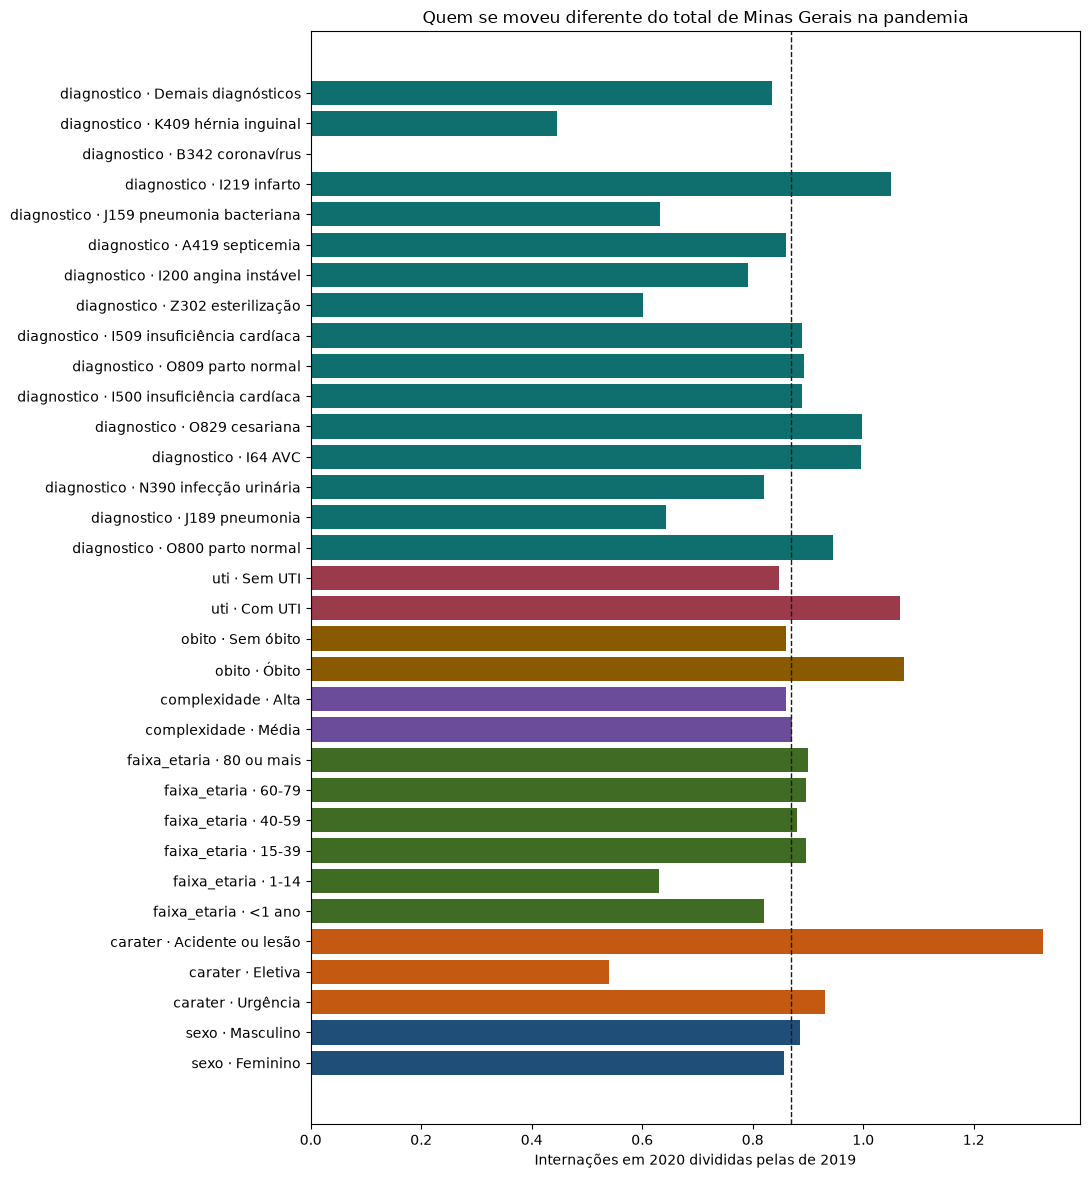

In [3]:
fig, eixo = plt.subplots(figsize=(11, max(5.2, 0.36 * len(decisao))))
rotulos = decisao["dimensao"] + " · " + decisao["grupo"]
cores = [CORES[list(ORDEM).index(dim) % len(CORES)] for dim in decisao["dimensao"]]
eixo.barh(rotulos, decisao["internacoes_2020_sobre_2019"], color=cores)
eixo.axvline(decisao["estado_2020_sobre_2019"].iloc[0], color="#1c1917", linestyle="--", linewidth=1)
eixo.set_xlabel("Internações em 2020 divididas pelas de 2019")
eixo.set_title("Quem se moveu diferente do total de Minas Gerais na pandemia")
fig.tight_layout()
fig.savefig(PASTA / "descritiva_mg_pandemia.png", dpi=120, bbox_inches="tight")
plt.show()


## Como os gráficos estão organizados

Para cada quebra há duas figuras. A primeira é a contagem mensal de julho de 2008 a julho de 2026, com um ponto por ano no eixo, para ver nível e tendência. A segunda é janeiro de 2023 a julho de 2026, em participação no total do mês, com a data em pé, para ver a sazonalidade de perto.

In [4]:
def serie_larga(dimensao: str) -> pd.DataFrame:
    fatia = base.loc[base["dimensao"].eq(dimensao)]
    largo = fatia.pivot(index="mes", columns="grupo", values="internacoes").fillna(0)
    return largo.reindex(columns=[g for g in ORDEM[dimensao] if g in largo.columns])


def desenhar(dimensao: str, titulo: str) -> None:
    largo = serie_larga(dimensao)
    recente = largo.loc["2023-01-01":"2026-07-01"]
    participacao = recente.div(total.reindex(recente.index), axis=0)

    fig, eixo = plt.subplots(figsize=(11, 4.2))
    for cor, grupo in zip(CORES, largo.columns):
        eixo.plot(largo.index, largo[grupo], label=grupo, color=cor, linewidth=1.4)
    eixo.set_title(f"{titulo}: contagem mensal")
    eixo.set_ylabel("internações")
    eixo.xaxis.set_major_locator(mdates.YearLocator())
    eixo.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    eixo.legend(ncol=3, fontsize=9, frameon=False)
    fig.tight_layout()
    fig.savefig(PASTA / f"descritiva_mg_{dimensao}_contagem.png", dpi=120, bbox_inches="tight")
    plt.show()

    fig, eixo = plt.subplots(figsize=(11, 4.6))
    for cor, grupo in zip(CORES, participacao.columns):
        eixo.plot(participacao.index, participacao[grupo], label=grupo, color=cor, linewidth=1.8)
    eixo.set_title(f"{titulo}: participação no total, de 2023 a julho de 2026")
    eixo.set_ylabel("fração do mês")
    eixo.set_ylim(0, 1)
    eixo.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    eixo.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    eixo.tick_params(axis="x", labelrotation=90, labelsize=8)
    eixo.legend(ncol=3, fontsize=9, frameon=False)
    fig.tight_layout()
    fig.savefig(PASTA / f"descritiva_mg_{dimensao}_participacao.png", dpi=120, bbox_inches="tight")
    plt.show()

## Sexo

Dois grupos, os dois grandes. A pergunta é se homem e mulher sobem e descem juntos. Se a participação fica estável e a correlação com o total é alta, separar o sexo cria duas séries com a mesma forma.

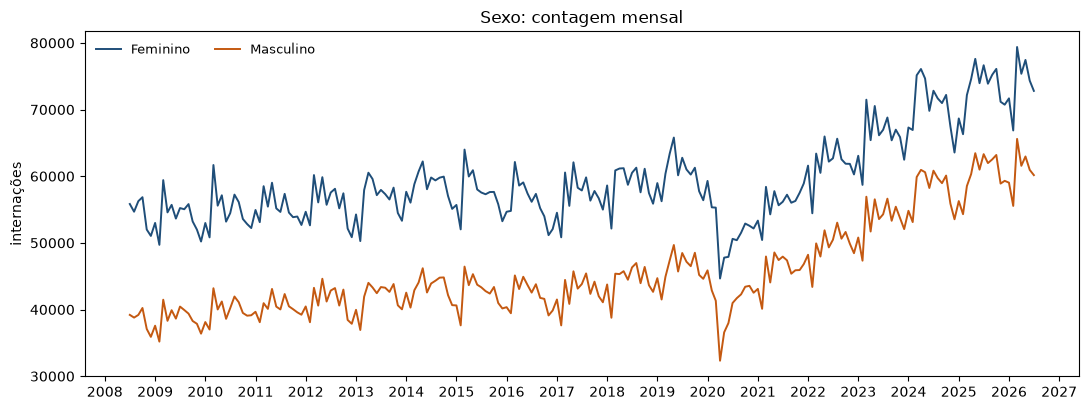

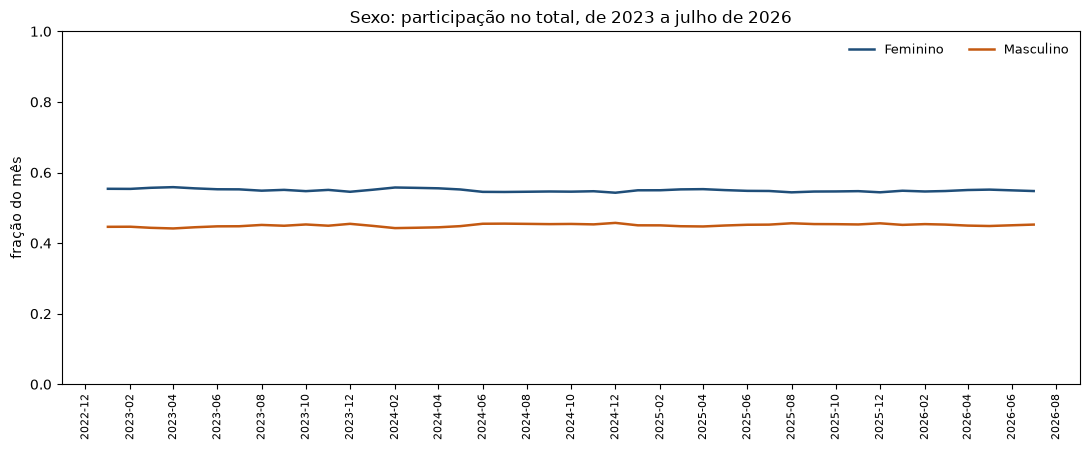

In [5]:
desenhar("sexo", "Sexo")

## Caráter da internação

`01` é eletiva e `02` é urgência. Os códigos `03` a `06` (acidente de trabalho, trajeto, trânsito e outras lesões) ficam juntos em “acidente ou lesão”, porque cada um é pequeno. A eletiva é o grupo que costuma cair quando o hospital reduz cirurgia programada. Se a razão 2020/2019 da eletiva ficar longe da urgência, essa quebra tem movimento próprio.

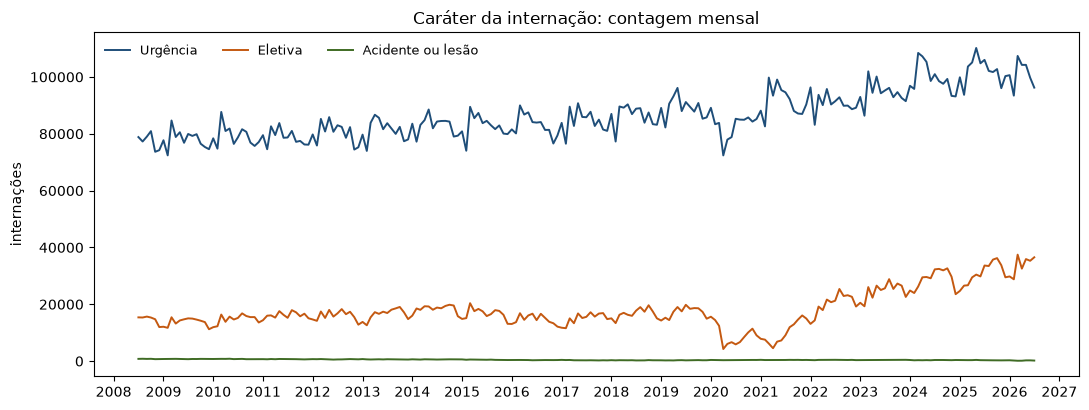

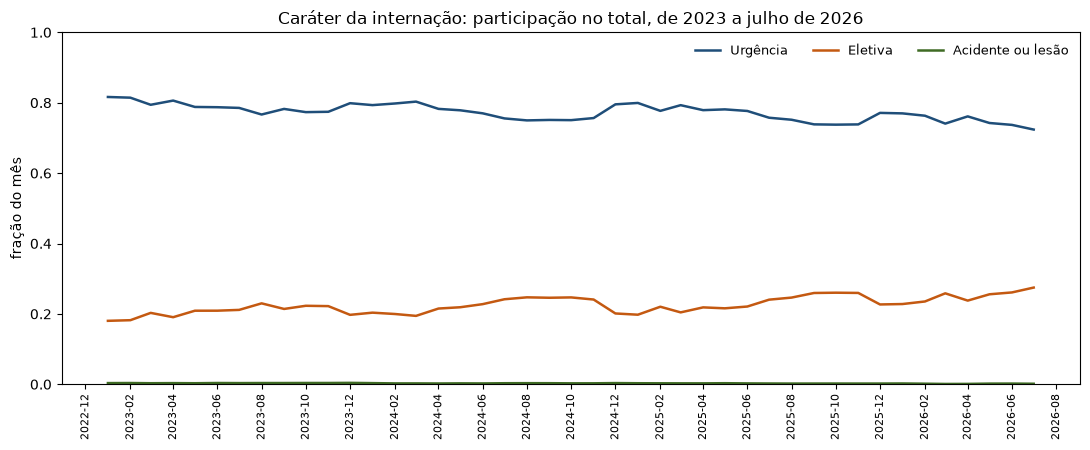

In [6]:
desenhar("carater", "Caráter da internação")

## Faixa etária

A idade em anos usa `COD_IDADE`: `4` é a idade em anos, `5` soma 100, `2` e `3` são dias e meses e entram em menor de 1 ano. Os cortes são menor de 1 ano, 1 a 14, 15 a 39, 40 a 59, 60 a 79 e 80 ou mais. Uma faixa boa para virar série tem volume e uma sazonalidade visível na figura de participação. Faixa muito fina, em um estado só, oscila mês a mês.

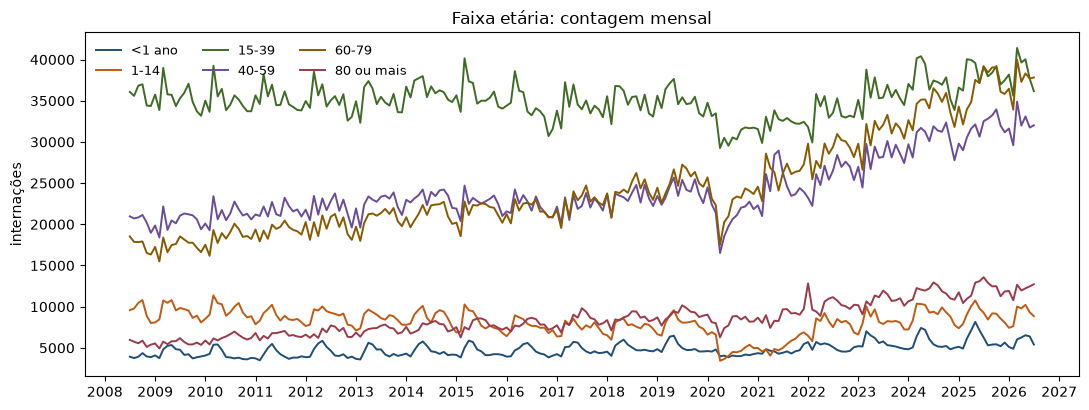

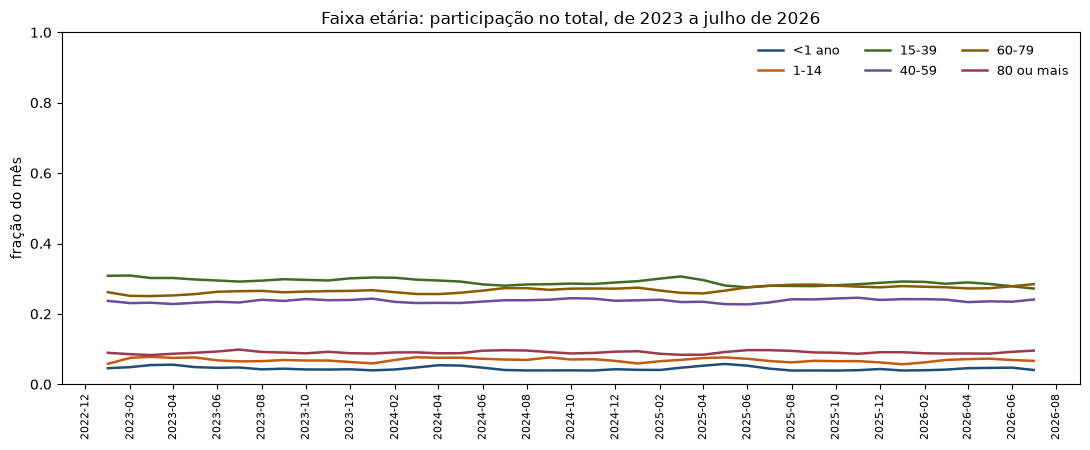

In [7]:
desenhar("faixa_etaria", "Faixa etária")

## Complexidade

`02` é média complexidade e `03` é alta. No arquivo de Minas Gerais a atenção básica quase não aparece entre as internações. Alta complexidade é a série menor. Vale olhar se ela tem sazonalidade própria ou se apenas acompanha a média, num patamar mais baixo.

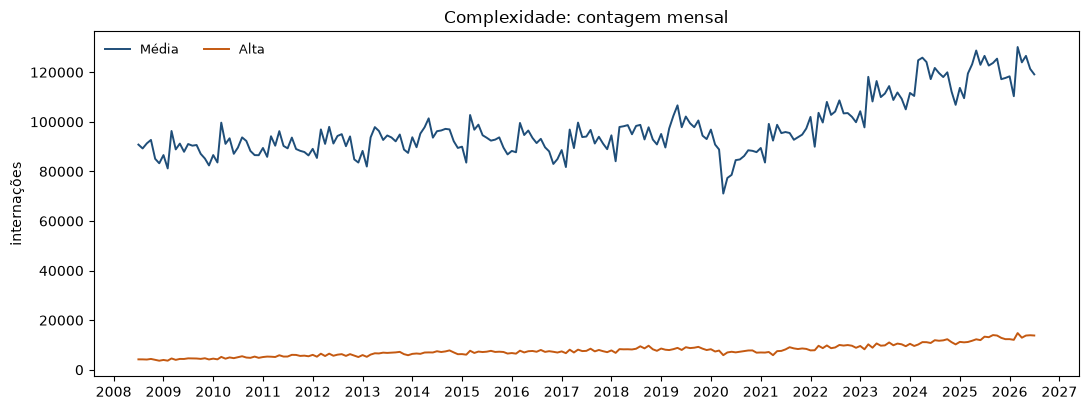

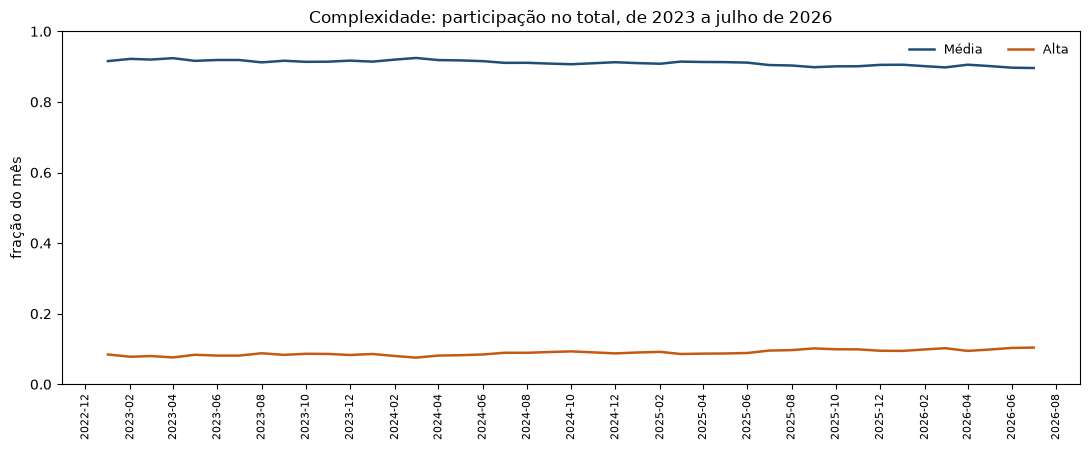

In [8]:
desenhar("complexidade", "Complexidade")

## Diagnóstico principal

O diagnóstico é o campo `DIAG_PRINC`, no código da CID-10 gravado na AIH. As quinze maiores são os quinze códigos com mais internações em Minas Gerais no período inteiro, de julho de 2008 a julho de 2026. Esse ranking fica fixo: o mesmo código permanece na série em todos os meses. Todo o resto entra em uma única série, “Demais diagnósticos”.

Dois códigos podem ser o mesmo quadro com final diferente. `O800` e `O809` são parto normal. `I500` e `I509` são insuficiência cardíaca. `J189` e `J159` são pneumonia. A primeira figura mostra cada código. A seguinte junta os quinze e compara com o restante.


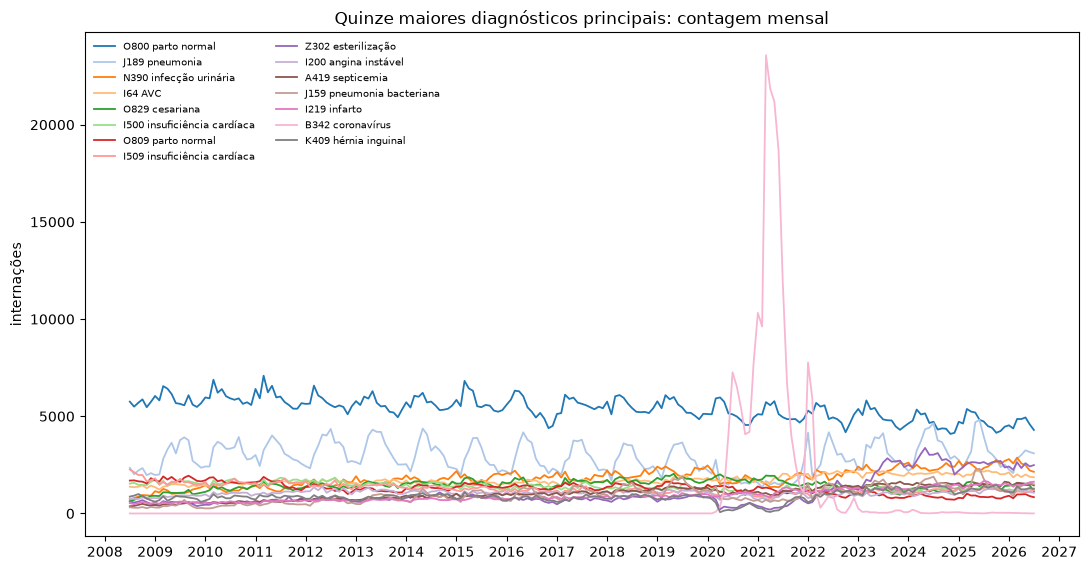

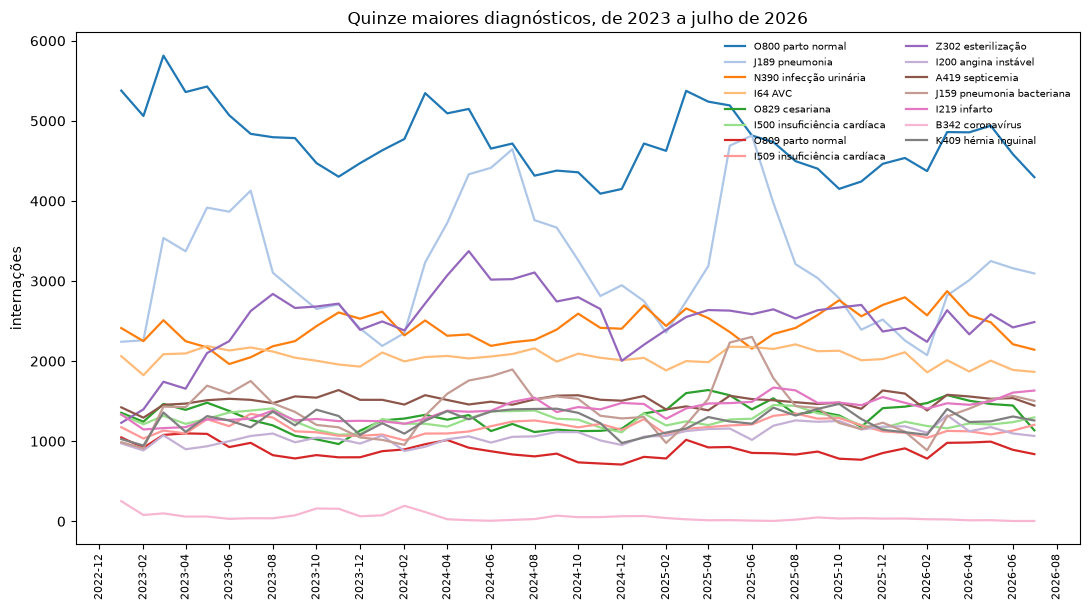

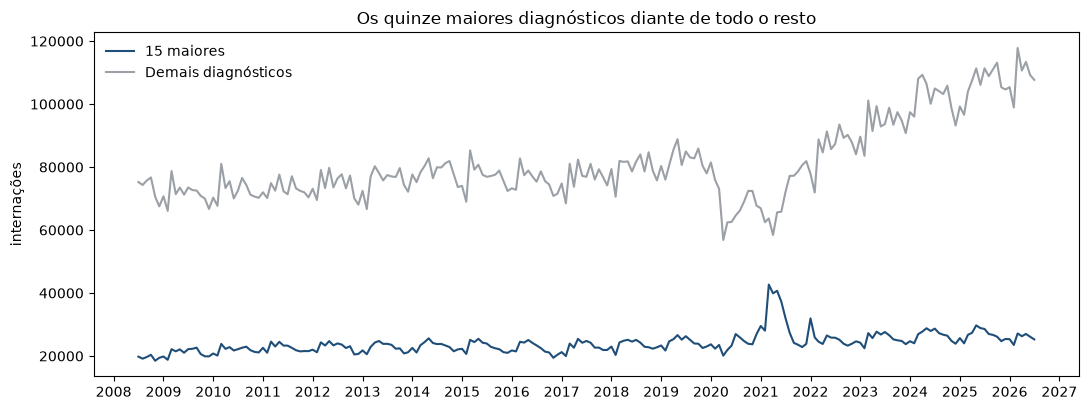

Os quinze maiores códigos são 22.9% das internações.
   dimensao                       grupo  media_mensal  participacao_%  correlacao_com_o_total  internacoes_2020_sobre_2019  estado_2020_sobre_2019
diagnostico           O800 parto normal       5402.90            5.14                   -0.49                         0.94                    0.87
diagnostico              J189 pneumonia       2875.82            2.74                    0.36                         0.64                    0.87
diagnostico      N390 infecção urinária       1832.00            1.74                    0.73                         0.82                    0.87
diagnostico                     I64 AVC       1727.59            1.64                    0.81                         1.00                    0.87
diagnostico              O829 cesariana       1457.87            1.39                   -0.03                         1.00                    0.87
diagnostico I500 insuficiência cardíaca       1393.71            

In [9]:
def desenhar_diagnostico() -> None:
    largo = serie_larga("diagnostico")
    dez = [grupo for grupo in largo.columns if grupo != DEMAIS]
    paleta = plt.cm.tab20.colors
    recente = largo.loc["2023-01-01":"2026-07-01", dez]

    fig, eixo = plt.subplots(figsize=(11, 5.8))
    for cor, grupo in zip(paleta, dez):
        eixo.plot(largo.index, largo[grupo], label=grupo, color=cor, linewidth=1.3)
    eixo.set_title("Quinze maiores diagnósticos principais: contagem mensal")
    eixo.set_ylabel("internações")
    eixo.xaxis.set_major_locator(mdates.YearLocator())
    eixo.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    eixo.legend(ncol=2, fontsize=7.5, frameon=False)
    fig.tight_layout()
    fig.savefig(PASTA / "descritiva_mg_diagnostico_contagem.png", dpi=120, bbox_inches="tight")
    plt.show()

    fig, eixo = plt.subplots(figsize=(11, 6.2))
    for cor, grupo in zip(paleta, dez):
        eixo.plot(recente.index, recente[grupo], label=grupo, color=cor, linewidth=1.6)
    eixo.set_title("Quinze maiores diagnósticos, de 2023 a julho de 2026")
    eixo.set_ylabel("internações")
    eixo.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    eixo.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    eixo.tick_params(axis="x", labelrotation=90, labelsize=8)
    eixo.legend(ncol=2, fontsize=7.5, frameon=False)
    fig.tight_layout()
    fig.savefig(PASTA / "descritiva_mg_diagnostico_recente.png", dpi=120, bbox_inches="tight")
    plt.show()

    juntos = pd.DataFrame(
        {
            "15 maiores": largo[dez].sum(axis=1),
            DEMAIS: largo[DEMAIS],
        }
    )
    fig, eixo = plt.subplots(figsize=(11, 4.2))
    eixo.plot(juntos.index, juntos["15 maiores"], color="#1f4e79", label="15 maiores", linewidth=1.5)
    eixo.plot(juntos.index, juntos[DEMAIS], color="#9aa0a6", label=DEMAIS, linewidth=1.5)
    eixo.set_title("Os quinze maiores diagnósticos diante de todo o resto")
    eixo.set_ylabel("internações")
    eixo.xaxis.set_major_locator(mdates.YearLocator())
    eixo.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    eixo.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(PASTA / "descritiva_mg_diagnostico_demais.png", dpi=120, bbox_inches="tight")
    plt.show()

    fatia = decisao.loc[decisao["dimensao"].eq("diagnostico")].copy()
    print(f"Os quinze maiores códigos são {fatia.loc[fatia['grupo'] != DEMAIS, 'participacao_%'].sum():.1f}% das internações.")
    print(fatia.round(2).to_string(index=False))


desenhar_diagnostico()


## Quantos diagnósticos passam do percentil 50

O percentil 50 é a mediana dos códigos, não das internações. Ordena-se cada `DIAG_PRINC` pelo total de internações no período. A mediana é o código do meio dessa lista. Em Minas Gerais esse código do meio teve 67 internações em dezoito anos.

Acima dessa mediana fica a metade dos códigos com mais volume. Como a distribuição é muito desigual, essa metade ainda inclui códigos raros e, somada, cobre quase todas as internações. O número que responde “quantas doenças são de fato as principais” é outro: quantos códigos, a partir do maior, são necessários para chegar à metade das internações.


In [10]:
ranking = pd.read_parquet(PASTA / "descritiva_mg_diagnosticos.parquet")["internacoes"].sort_values(ascending=False)
limite = float(ranking.quantile(0.5))
acima = ranking.loc[ranking > limite]
acumulado = ranking.cumsum() / ranking.sum()
ate_metade = int((acumulado < 0.5).sum() + 1)
ate_oitenta = int((acumulado < 0.8).sum() + 1)

print(f"Códigos distintos: {len(ranking):,}".replace(",", "."))
print(f"Percentil 50: {limite:.0f} internações no período inteiro")
print(f"Códigos acima do percentil 50: {len(acima):,}".replace(",", "."))
print(f"Esses códigos cobrem {100 * acima.sum() / ranking.sum():.1f}% das internações")
print(f"Códigos necessários para 50% das internações: {ate_metade}")
print(f"Códigos necessários para 80% das internações: {ate_oitenta}")

acima.rename("internacoes").to_frame().to_parquet(PASTA / "descritiva_mg_diagnosticos_acima_p50.parquet")

principais = ranking.head(ate_metade).rename("internacoes").reset_index()
principais["participacao_%"] = 100 * principais["internacoes"] / ranking.sum()
principais["acumulado_%"] = principais["participacao_%"].cumsum()
principais


Códigos distintos: 10.389
Percentil 50: 67 internações no período inteiro
Códigos acima do percentil 50: 5.181
Esses códigos cobrem 99.6% das internações
Códigos necessários para 50% das internações: 94
Códigos necessários para 80% das internações: 550


,DIAG_PRINC,internacoes,participacao_%,acumulado_%
0,O800,1172429,5.139939,5.139939
1,J189,624054,2.735858,7.875798
2,N390,397544,1.742836,9.618634
3,I64,374887,1.643508,11.262142
4,O829,316358,1.386916,12.649058
...,...,...,...,...
89,F200,40975,0.179635,49.406541
90,K818,40946,0.179508,49.586049
91,N40,40327,0.176794,49.762843
92,J441,40042,0.175544,49.938387


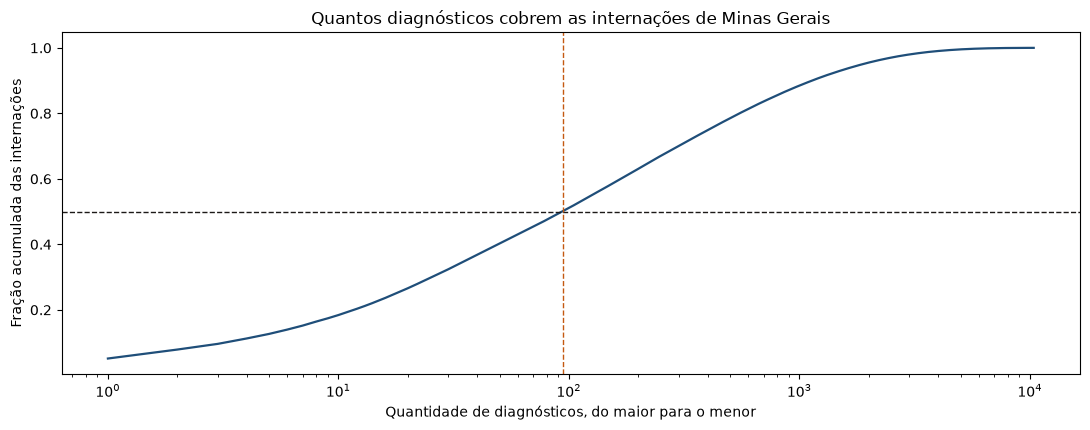

In [11]:
fig, eixo = plt.subplots(figsize=(11, 4.4))
eixo.plot(range(1, len(acumulado) + 1), acumulado.to_numpy(), color="#1f4e79", linewidth=1.6)
eixo.axhline(0.5, color="#1c1917", linestyle="--", linewidth=1)
eixo.axvline(ate_metade, color="#c45911", linestyle="--", linewidth=1)
eixo.set_xscale("log")
eixo.set_xlabel("Quantidade de diagnósticos, do maior para o menor")
eixo.set_ylabel("Fração acumulada das internações")
eixo.set_title("Quantos diagnósticos cobrem as internações de Minas Gerais")
fig.tight_layout()
fig.savefig(PASTA / "descritiva_mg_diagnostico_percentil.png", dpi=120, bbox_inches="tight")
plt.show()


## Óbito e UTI

Aqui a linha principal não reparte o total. “Óbito” é a internação com `MORTE` = 1, o óbito ocorrido durante a internação, não o óbito depois da alta. “Com UTI” é a internação com pelo menos um dia em `UTI_MES_TO`. As duas figuras de baixo mostram a taxa por 100 internações do mês, que é o que se compara ao longo do tempo. A taxa de óbito muda devagar. A taxa de UTI diz se a série de terapia intensiva é estável o bastante para prever.

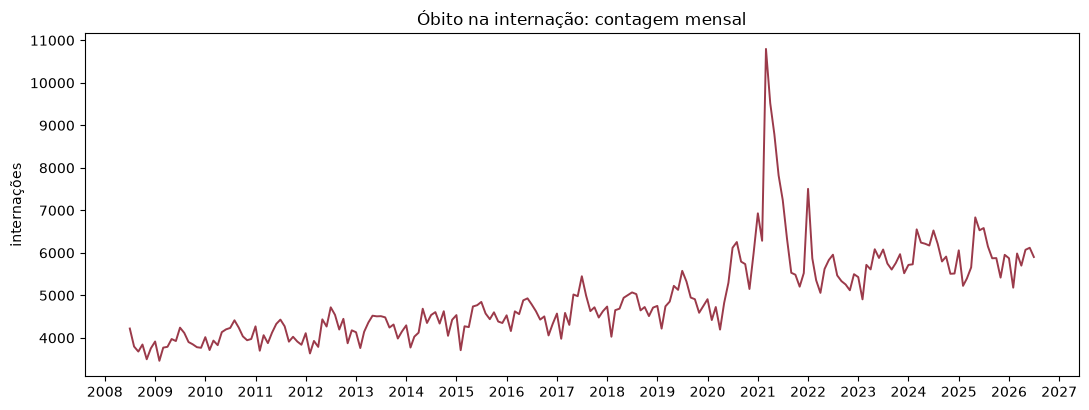

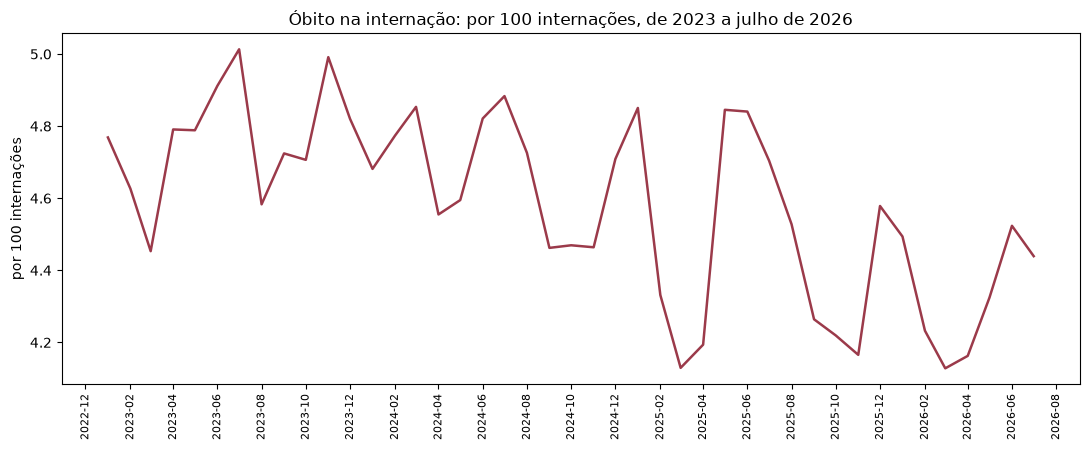

Óbito na internação: média de 4.7 por 100 internações no período inteiro.


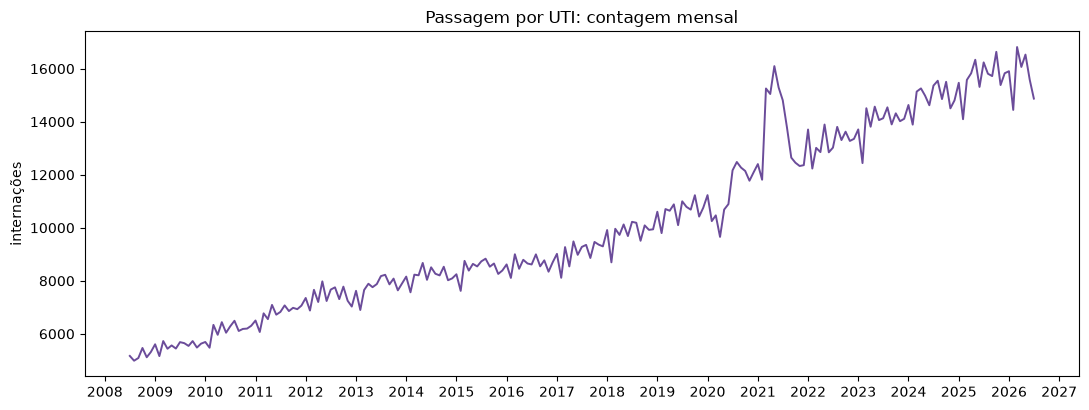

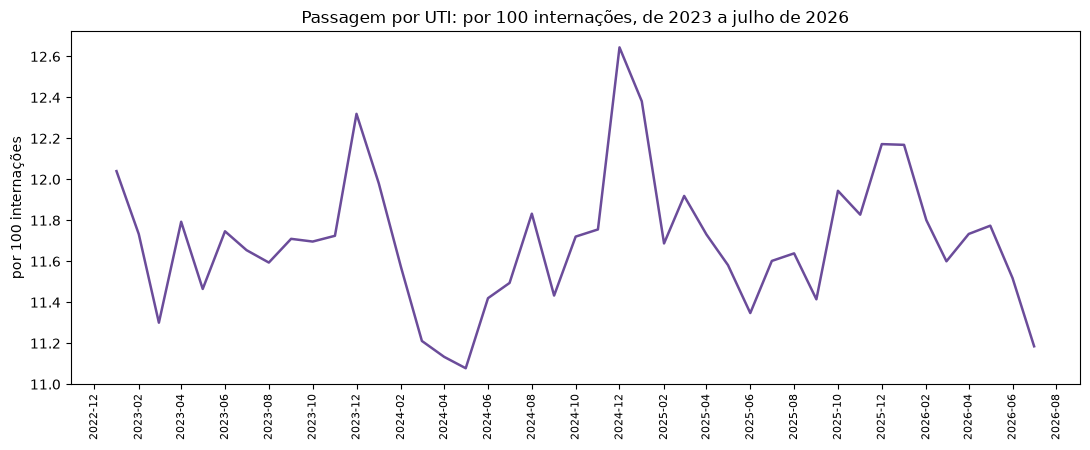

Passagem por UTI: média de 9.5 por 100 internações no período inteiro.


In [12]:
def desenhar_taxa(dimensao: str, grupo: str, titulo: str, cor: str) -> None:
    largo = serie_larga(dimensao)
    contagem = largo[grupo]
    taxa = 100 * contagem / total.reindex(contagem.index)
    recente = taxa.loc["2023-01-01":"2026-07-01"]

    fig, eixo = plt.subplots(figsize=(11, 4.2))
    eixo.plot(contagem.index, contagem, color=cor, linewidth=1.4)
    eixo.set_title(f"{titulo}: contagem mensal")
    eixo.set_ylabel("internações")
    eixo.xaxis.set_major_locator(mdates.YearLocator())
    eixo.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.tight_layout()
    fig.savefig(PASTA / f"descritiva_mg_{dimensao}_contagem.png", dpi=120, bbox_inches="tight")
    plt.show()

    fig, eixo = plt.subplots(figsize=(11, 4.6))
    eixo.plot(recente.index, recente, color=cor, linewidth=1.8)
    eixo.set_title(f"{titulo}: por 100 internações, de 2023 a julho de 2026")
    eixo.set_ylabel("por 100 internações")
    eixo.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    eixo.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    eixo.tick_params(axis="x", labelrotation=90, labelsize=8)
    fig.tight_layout()
    fig.savefig(PASTA / f"descritiva_mg_{dimensao}_taxa.png", dpi=120, bbox_inches="tight")
    plt.show()
    print(f"{titulo}: média de {taxa.mean():.1f} por 100 internações no período inteiro.")


desenhar_taxa("obito", "Óbito", "Óbito na internação", "#9b3a4a")
desenhar_taxa("uti", "Com UTI", "Passagem por UTI", "#6b4c9a")

## Leitura para a decisão

Sexo tende a ser uma escala do total: os dois grupos são grandes e caminham juntos. Caráter é o candidato mais claro quando a eletiva e a urgência divergem em 2020. Faixa etária vale quando alguma faixa, em geral a de criança ou a de 80 ou mais, tem sazonalidade que o total esconde. Complexidade só se justifica se a alta não for uma cópia menor da média. Óbito e UTI são outras séries, não pedaços do total: entram se a taxa mensal for estável o bastante para prever, o que as figuras de 2023 a 2026 mostram.

O diagnóstico principal é o corte mais específico. Os quinze maiores códigos, juntos, continuam sendo uma minoria do volume. O restante fica em uma série só. Vale série própria o código que tem volume visível na figura e uma sazonalidade que o total não tem, como a pneumonia no inverno. Parto normal e cesariana caminham mais estáveis.

Esta leitura é de Minas Gerais. Um estado pequeno pode ter a mesma forma e muito mais ruído na faixa mais fina.
